# 01 — Exploratory Data Analysis
Pharma Commercial Performance & Market Insights Platform

This notebook explores the cleaned datasets in `data/processed/` and
reproduces the core visuals for **Module 1: Commercial Performance**.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 5)

PROCESSED_DIR = os.path.join("..", "data", "processed")

In [2]:
products = pd.read_csv(os.path.join(PROCESSED_DIR, "product_master.csv"))
hcps = pd.read_csv(os.path.join(PROCESSED_DIR, "hcp_master.csv"))
sales = pd.read_csv(os.path.join(PROCESSED_DIR, "sales_transactions.csv"), parse_dates=["date"])
presc = pd.read_csv(os.path.join(PROCESSED_DIR, "prescriptions.csv"), parse_dates=["date"])
market = pd.read_csv(os.path.join(PROCESSED_DIR, "market_data.csv"), parse_dates=["month"])

print(products.shape, hcps.shape, sales.shape, presc.shape, market.shape)
products.head()

(15, 7) (350, 7) (23957, 9) (24230, 6) (540, 8)


,product_id,brand_name,therapy_area,molecule,dosage_form,launch_date,price
0,P001,ONCO-A1,Oncology,Molecule-ON1,Tablet,2021-08-01,"3,870.76"
1,P002,ONCO-B2,Oncology,Molecule-ON2,Capsule,2016-09-01,469.09
2,P003,ONCO-C3,Oncology,Molecule-ON3,Capsule,2022-09-01,"3,547.99"
3,P004,CARD-A4,Cardiology,Molecule-CA1,Syrup,2019-02-01,"2,054.22"
4,P005,CARD-B5,Cardiology,Molecule-CA2,Capsule,2018-03-01,"2,915.20"


## Monthly net sales trend

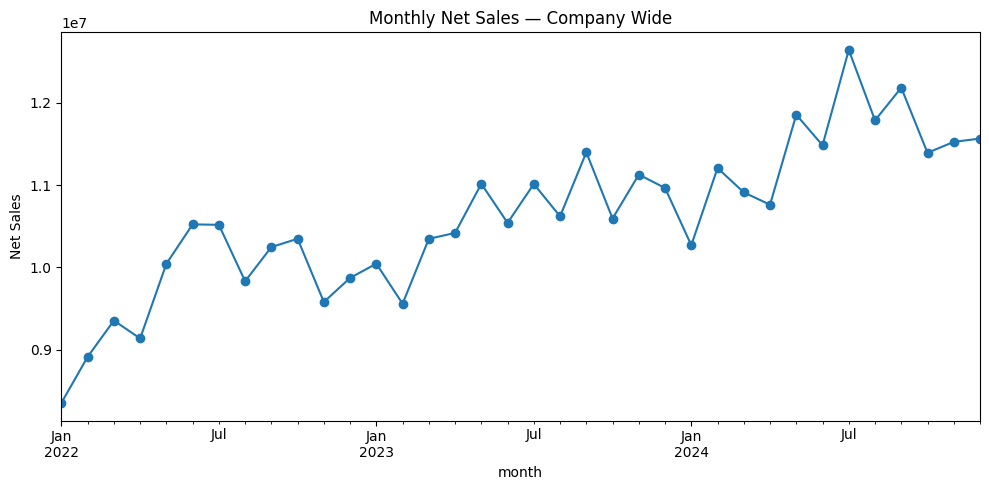

In [3]:
sales["month"] = sales["date"].values.astype("datetime64[M]")
monthly_sales = sales.groupby("month")["net_sales"].sum()

monthly_sales.plot(marker="o", title="Monthly Net Sales — Company Wide")
plt.ylabel("Net Sales")
plt.tight_layout()
plt.show()

## Sales by product (Pareto view)

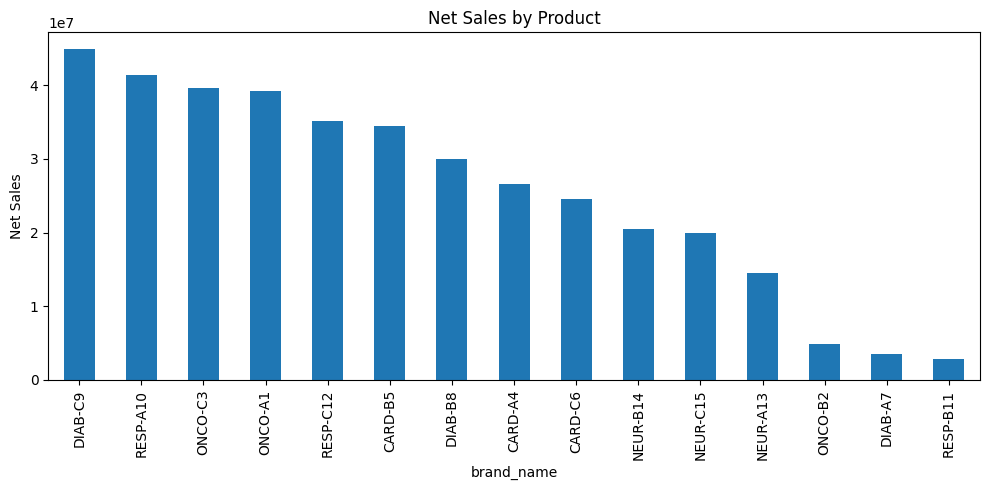

In [4]:
sales_by_product = (
    sales.merge(products[["product_id", "brand_name"]], on="product_id")
    .groupby("brand_name")["net_sales"]
    .sum()
    .sort_values(ascending=False)
)
sales_by_product.plot(kind="bar", title="Net Sales by Product")
plt.ylabel("Net Sales")
plt.tight_layout()
plt.show()

## Sales by region

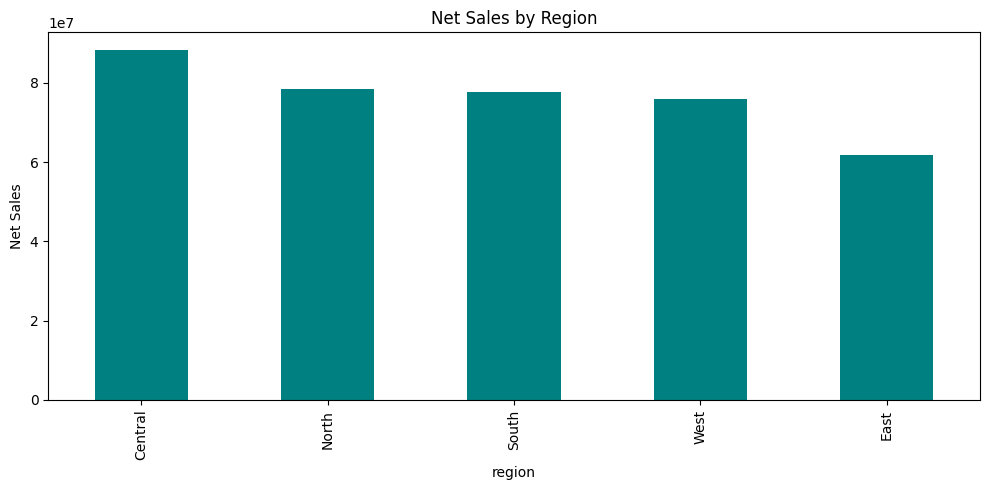

In [5]:
sales_by_region = sales.groupby("region")["net_sales"].sum().sort_values(ascending=False)
sales_by_region.plot(kind="bar", title="Net Sales by Region", color="teal")
plt.ylabel("Net Sales")
plt.tight_layout()
plt.show()

## Sales vs prescriptions relationship (are we underperforming vs Rx anywhere?)

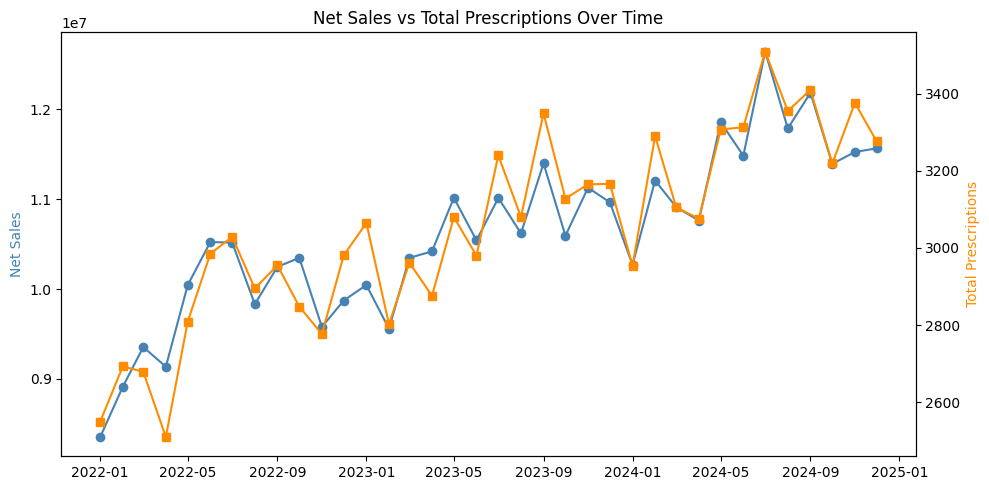

In [6]:
presc["month"] = presc["date"].values.astype("datetime64[M]")
monthly_rx = presc.groupby("month")["total_prescriptions"].sum()

fig, ax1 = plt.subplots()
ax1.plot(monthly_sales.index, monthly_sales.values, color="steelblue", marker="o", label="Net Sales")
ax1.set_ylabel("Net Sales", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(monthly_rx.index, monthly_rx.values, color="darkorange", marker="s", label="Total Prescriptions")
ax2.set_ylabel("Total Prescriptions", color="darkorange")
plt.title("Net Sales vs Total Prescriptions Over Time")
fig.tight_layout()
plt.show()

## Market share snapshot (latest month)

In [7]:
latest_month = market["month"].max()
latest = market[market["month"] == latest_month].sort_values("market_share", ascending=False)
latest[["product", "therapy_area", "market_share", "company_sales", "competitor_sales"]]

,product,therapy_area,market_share,company_sales,competitor_sales
214,CARD-B5,Cardiology,0.26,"1,270,549.05","2,109,575.37"
105,ONCO-A1,Oncology,0.24,"1,279,324.45","2,638,264.65"
107,ONCO-C3,Oncology,0.24,"1,271,429.89","2,638,264.65"
431,RESP-C12,Respiratory,0.23,"1,157,232.07","2,704,721.21"
429,RESP-A10,Respiratory,0.22,"1,136,141.89","2,704,721.21"
213,CARD-A4,Cardiology,0.19,"966,885.94","2,109,575.37"
323,DIAB-C9,Diabetes,0.15,"1,131,344.60","5,361,861.25"
322,DIAB-B8,Diabetes,0.14,"1,054,121.49","5,361,861.25"
215,CARD-C6,Cardiology,0.12,"613,354.52","2,109,575.37"
538,NEUR-B14,Neurology,0.09,"595,425.34","4,981,124.21"


## Summary
- Net sales show a mild upward trend with seasonal dips/peaks.
- A small set of products drive a disproportionate share of revenue
  (see cumulative % in the SQL Pareto query for the exact breakdown).
- Sales and prescription volume trends move together, as expected,
  with periodic gaps worth investigating region-by-region using the
  `monthly_kpi_summary.csv` feature table.